# Chapitre 6 - Exercices 6.1 à 6.6

Ce notebook traite les six premiers exercices du chapitre 6, centrés sur le choix
d'une clé de partitionnement et sur le rééquilibrage :

- **6.1** : choisir une clé de partitionnement pour trois applications (raisonnement
  et simulation) ;
- **6.2** : le hachage ne garantit l'équilibre qu'en moyenne, « balles dans des
  urnes » (calcul et simulation) ;
- **6.3** : modulo N, nombre fixe de partitions et anneau à jetons : clés déplacées
  et nombre de jetons par nœud (démonstration et vérification) ;
- **6.4** : dimensionner un nombre fixe de partitions pour un jeu de données qui
  croît d'un facteur 100 (calcul) ;
- **6.5** : partitionnement dynamique avec fusion des petites partitions, et le
  piège de l'oscillation (mini-lab) ;
- **6.6** : éclater une clé chaude par salage : combien de suffixes, et que faire
  des lectures ? (calcul et simulation).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 6.1 : choisir une clé de partitionnement

**Énoncé.** Pour chacune des trois applications suivantes, on dispose de 8
partitions. Proposer une clé de partitionnement et un schéma (par plage
de clés ou par hachage), en justifiant par les requêtes à servir.

1. **Capteurs.** 500 capteurs envoient chacun une mesure toutes les 10 minutes. Requêtes :
   (a) « toutes les mesures de tous les capteurs entre 10 h et 11 h hier » ; (b)
   « l'historique complet du capteur 42 ». On compare trois clés : l'horodatage seul (par
   plage, une partition par jour), le couple (capteur, horodatage) par plage, et le
   couple (capteur, horodatage) avec hachage du seul identifiant de capteur.
2. **Commandes d'un site marchand.** Requêtes : afficher une commande ; lister les
   commandes d'un client. Clé : identifiant de commande haché, ou identifiant de client
   haché ?
3. **Messages d'un réseau social**, clé = identifiant de l'auteur hachée. La popularité
   des comptes suit une loi de Zipf. La répartition des **lectures** est-elle équitable ?

Vérifier chaque réponse en mesurant le déséquilibre (charge maximale / charge moyenne)
et le nombre de partitions qu'une requête doit interroger.

**Rappels.** Par plage de clés, les clés voisines sont ensemble : les requêtes de plage
sont efficaces mais des écritures sur des clés voisines (horodatages) créent un point
chaud. Par hachage, la charge s'étale mais l'ordre est perdu ; seule la partie hachée de
la clé décide de la partition, le reste peut servir à trier (cours 1, sections
*Partitioning by Key Range* et
*Partitioning by Hash of Key*). Hacher ne règle pas
le cas d'une clé très demandée (cours 3, section *Skewed Workloads and Relieving Hot
Spots*).

**Solution.**

*1. Capteurs.* Avec l'horodatage seul, toutes les écritures d'une journée vont dans
la même partition : déséquilibre en écriture égal à 8 (une partition travaille, sept
dorment). La requête (a) est idéale (une seule partition, un parcours de plage) ; la
requête (b) touche les 8 partitions. Avec (capteur, horodatage), les écritures
s'étalent, (b) devient un parcours de plage dans une seule partition, mais (a) exige
**une requête de plage par capteur**, soit 500 requêtes réparties sur toutes les
partitions. Comme on écrit en continu et qu'on lit l'historique d'un capteur, c'est
le bon choix ; la requête (a), plus rare, se paie. Par plage ou par hachage de
l'identifiant de capteur, les deux variantes se valent ici ; la plage donne un meilleur
équilibre parce que les identifiants sont denses et de charge égale, le hachage de 500
valeurs seulement laisse un déséquilibre visible (15 %, voir l'exercice 6.2).

*2. Commandes.* Hacher l'identifiant de **client** place toutes les commandes d'un client
ensemble : « lister les commandes d'un client » touche une partition, et l'affichage
d'une commande aussi pourvu que l'identifiant de commande contienne celui du client (clé
composée (client, commande), le client servant de clé de partitionnement et la commande
de clé de tri). Hacher l'identifiant de commande équilibre parfaitement mais oblige à
interroger toutes les partitions (ou un index secondaire global) pour la liste d'un
client.

*3. Réseau social.* Le hachage répartit les **comptes** équitablement, pas la
**charge** : les lectures d'un compte célèbre arrivent toutes sur
la même partition. Si le compte le plus lu reçoit une part des lectures supérieure à 1/8, aucun
schéma de partitionnement par auteur ne peut équilibrer ; il faut des répliques, un cache,
ou un traitement spécial des clés chaudes.

**Vérification.** Huit jours de mesures simulées (`P.sensor_readings`), puis 100 000
comptes avec des lectures en loi de Zipf d'exposant 1,1.

In [2]:
N = 8
sid, t = P.sensor_readings(500, 8 * 86400, 1 / 600, seed=1)
jour = (t // 86400).astype(int)
schemas = {
    "horodatage (plage, 1 par jour)": jour,
    "(capteur, horodatage) par plage": (sid * N) // 500,
    "(capteur, horodatage), capteur haché": (P.mix64(sid) % np.uint64(N)).astype(int),
}
rows = []
for nom, sh in schemas.items():
    imb = np.mean([P.imbalance(P.shard_loads(sh[jour == d], N)) for d in range(8)])
    req_a = len(np.unique(sh[(jour == 6) & ((t % 86400) // 3600 == 10)]))
    req_b = len(np.unique(sh[sid == 42]))
    rows.append({"clé": nom, "déséquilibre en écriture (par jour)": imb,
                 "partitions lues, requête (a)": req_a,
                 "requêtes de plage, (a)": 1 if nom.startswith("horo") else 500,
                 "partitions lues, requête (b)": req_b})
tab = pd.DataFrame(rows).set_index("clé")
print(f"{fmt(len(sid))} mesures simulées")
tab

576 025 mesures simulées


,déséquilibre en écriture (par jour),"partitions lues, requête (a)","requêtes de plage, (a)","partitions lues, requête (b)"
clé,,,,
"horodatage (plage, 1 par jour)",8.000,1,1,8
"(capteur, horodatage) par plage",1.019,8,500,1
"(capteur, horodatage), capteur haché",1.154,8,500,1


In [3]:
cmd_client = rng.integers(0, 20_000, 200_000)          # client de chaque commande
cmd_id = np.arange(cmd_client.size)
par_cmd = (P.mix64(cmd_id) % np.uint64(N)).astype(int)
par_cli = (P.mix64(cmd_client) % np.uint64(N)).astype(int)
clients = rng.choice(20_000, 500, replace=False)
lues_cmd = np.mean([len(np.unique(par_cmd[cmd_client == c])) for c in clients])
lues_cli = np.mean([len(np.unique(par_cli[cmd_client == c])) for c in clients])
print(f"commandes par client : {cmd_client.size / 20_000:.0f} en moyenne")
print(f"lister les commandes d'un client : {lues_cmd:.2f} partitions lues (clé = commande) "
      f"contre {lues_cli:.2f} (clé = client)")
print(f"déséquilibre en volume : {P.imbalance(P.shard_loads(par_cmd, N)):.3f} (commande), "
      f"{P.imbalance(P.shard_loads(par_cli, N)):.3f} (client)")

commandes par client : 10 en moyenne
lister les commandes d'un client : 5.75 partitions lues (clé = commande) contre 1.00 (clé = client)
déséquilibre en volume : 1.008 (commande), 1.028 (client)


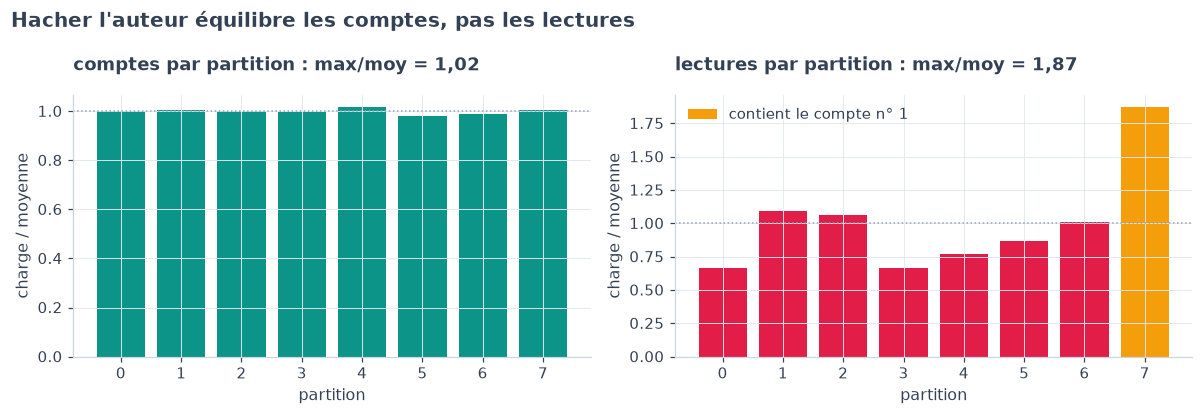

part des lectures du compte le plus populaire : 13.4% (1/8 = 12,5 %)


In [4]:
n_comptes = 100_000
lectures = P.zipf_requests(n_comptes, 1_000_000, s=1.1, seed=2)
part_compte = (P.mix64(np.arange(n_comptes)) % np.uint64(N)).astype(int)
charge = P.shard_loads(part_compte[lectures], N)
comptes = P.shard_loads(part_compte, N)
part_top = np.mean(lectures == 0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, val, titre, c in [(axes[0], comptes, "comptes par partition", TEAL),
                          (axes[1], charge, "lectures par partition", ROSE)]:
    ax.bar(range(N), val / val.mean(), color=c)
    ax.axhline(1, color=GRAY, ls=":", lw=1)
    ax.set_xlabel("partition"); ax.set_ylabel("charge / moyenne")
    ax.set_title(titre + f" : max/moy = {P.imbalance(val):.2f}".replace(".", ","))
axes[1].bar(part_compte[0], charge[part_compte[0]] / charge.mean(), color=AMBER, label="contient le compte n° 1")
axes[1].legend(loc="upper left")
finish(fig, "Hacher l'auteur équilibre les comptes, pas les lectures")
plt.show()
print(f"part des lectures du compte le plus populaire : {part_top:.1%} (1/8 = 12,5 %)")

Les chiffres confirment le raisonnement. Pour les capteurs, l'horodatage seul donne un
déséquilibre de 8 (toute la journée sur une partition) ; les deux clés composées
l'éliminent, la plage sur l'identifiant de capteur étant presque parfaite et le hachage
de 500 identifiants laissant un écart de quelques pour cent à une quinzaine de pour cent,
que l'exercice suivant explique. La requête (a) touche alors toutes les
partitions et coûte 500 parcours de plage, la requête (b) une seule. Pour les commandes, la clé
« client » ramène la liste d'un client à une seule partition contre 5,75 en moyenne avec la
clé « commande » (10 commandes par client, réparties au hasard sur 8). Pour le réseau social, le compte le plus lu attire à lui seul 13 %
des lectures : sa partition porte largement plus que la moyenne, quel que soit le
hachage.

> **À retenir.** On choisit la clé de partitionnement d'après les **requêtes** : la
> requête fréquente doit toucher une seule partition, les écritures doivent s'étaler.
> Une clé composée (clé de partitionnement, clé de tri) concilie souvent les deux. Et
> aucun schéma ne répartit une charge concentrée sur une seule clé.